# Labwork 3 - Stochastic optimization

**Week 2 - Day 3 - ~ 170 min at the keyboard**

Read Lecture 3 first. Today the exact gradient is replaced by a **sample** of it. Each
exercise is followed by the figures that measure what you just wrote.

> **The rule.** `interfaces.py`, `results.py`, `errors.py` and `types.py` are **provided** -
> never edit them. Everywhere else, replace each `raise NotImplementedError`, keeping the
> signature and honouring the docstring.

## Setup

Run this once. It points the notebook at your `optlab` clone, turns on `%autoreload` so
that the edits you make in `src/optlab/` are picked up here without restarting the kernel,
and gives you a `check()` helper that runs a test file and reports what happened.

`check()` only trims pytest's output so a failure stays readable. Anything else, run
directly with Jupyter's `!` escape - these are the real commands, and the ones you will
type in a terminal for the rest of your life:

```
!cd {OPTLAB} && make check          # the whole thing: tests + mypy + ruff
!cd {OPTLAB} && python -m mypy      # types only
!cd {OPTLAB} && python -m pytest -q -m day1
```

`!` runs each line in its own shell, so the `cd` has to sit on the same line as the
command.

In [2]:
%load_ext autoreload
%autoreload 2

import os
import subprocess
import sys
from pathlib import Path

# Adjust if your clone lives elsewhere.
OPTLAB = (Path.cwd() / ".." / ".." / "optlab").resolve()
assert OPTLAB.exists(), f"optlab not found at {OPTLAB} -- edit OPTLAB above"
if not (OPTLAB / "src" / "optlab" / "interfaces.py").exists():
    # Not a student clone. The teacher tree keeps only the solved files in src/ and
    # assembles a complete package in code/ (`make check`), so use that one. This branch
    # never fires for you; it is here so the correction notebook can be a plain copy of
    # this one instead of a second version that drifts.
    OPTLAB = OPTLAB / "code"
    assert OPTLAB.exists(), f"run `make check` in {OPTLAB.parent} first"
ROOT = OPTLAB
print("optlab:", OPTLAB)

# Prefer the installed package (`make install`); fall back to <root>/src if it is not.
try:
    import optlab
except ModuleNotFoundError:
    sys.path.insert(0, str(OPTLAB / "src"))
    import optlab
sys.path.insert(0, str(OPTLAB))  # for datasets/


def check(*pytest_args):
    """Run pytest inside the optlab clone and show a short report."""
    # pytest runs in a SUBPROCESS, and a subprocess does not inherit the sys.path entries
    # added above. Passing them through PYTHONPATH is what makes `check()` work before
    # `make install` has been run, instead of failing to import optlab in conftest.py.
    env = {**os.environ, "PYTHONPATH": os.pathsep.join(
        [str(OPTLAB / "src"), str(OPTLAB), os.environ.get("PYTHONPATH", "")]).rstrip(os.pathsep)}
    r = subprocess.run([sys.executable, "-m", "pytest", "-q", "--no-header", *pytest_args],
                       cwd=OPTLAB, capture_output=True, text=True, env=env)
    out = r.stdout + r.stderr
    tail = [l for l in out.splitlines() if l.strip()][-12:]
    print("\n".join(tail))
    if "No module named pytest" in out:
        verdict = "pytest is not installed -- run:  pip install -e '.[dev]'"
    elif r.returncode == 0:
        verdict = "PASSED"
    elif r.returncode == 5:
        # Exit code 5 means pytest collected nothing at all. That is NOT a failure of
        # your code: no test in the suite matches what was asked for. Some days have no
        # automated tests yet; judge those exercises by the checks written in the text.
        verdict = "no tests matched -- nothing to run here, this is not a failure"
    else:
        verdict = "not yet -- keep going"
    print()
    print(verdict)


def edit(relpath):
    """Print the absolute path of a source file, so you can open it in the editor."""
    print(OPTLAB / "src" / "optlab" / relpath)


check("tests/test_no_oracle_in_src.py")   # provided, and already green

optlab: /Users/hoangtom/Documents/CODE/USTH_ProgrammingTechniques/Week2/optlab
..............................                                           [100%]
30 passed in 0.04s

PASSED


In [3]:
import matplotlib.pyplot as plt
import numpy as np

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "font.size": 10,
                     "axes.titlesize": 10, "figure.dpi": 110})
rng = np.random.default_rng(20250921)

print("optlab root  :", ROOT)
print("optlab loaded:", Path(optlab.__file__).parent)

optlab root  : /Users/hoangtom/Documents/CODE/USTH_ProgrammingTechniques/Week2/optlab
optlab loaded: /Users/hoangtom/Documents/CODE/USTH_ProgrammingTechniques/Week2/optlab/src/optlab


In [4]:
def status(name, thunk):
    """Report whether one piece of the package is implemented, without a traceback."""
    try:
        thunk()
    except NotImplementedError:
        return f"  MISSING   {name}"
    except Exception as err:                      # noqa: BLE001 - we want to see anything
        return f"  BROKEN    {name}   ({type(err).__name__}: {err})"
    return f"  ok        {name}"

In [39]:
from optlab.losses import LogisticNLL, SquaredError
from optlab.observers import History
from optlab.optimizers import Adam, SGD, gradient_descent
from optlab.problems import GLMLoss, logistic_regression

_Xc, _yc = np.eye(2), np.array([1.0, 0.0])
_glm = GLMLoss(_Xc, _yc, SquaredError())
_w = np.zeros(2)

print("Day 3 readiness")
print(status("GLMLoss.n_samples", lambda: _glm.n_samples))
print(status("GLMLoss.batch_gradient", lambda: _glm.batch_gradient(_w, np.array([0]))))
print(status("SGD", lambda: SGD(batch_size=1, lr=0.1, n_epochs=1,
                                rng=np.random.default_rng(0)).minimize(_glm, _w)))
print(status("Adam", lambda: Adam(batch_size=1, lr=0.1, n_epochs=1,
                                  rng=np.random.default_rng(0)).minimize(_glm, _w)))
print()
print("Still needed from earlier days")
print(status("LogisticNLL", lambda: LogisticNLL().value(0.5, 1.0)))
print(status("GLMLoss.gradient", lambda: _glm.gradient(_w)))
print(status("gradient_descent (for the reference minimum)",
             lambda: gradient_descent(max_iter=3).minimize(_glm, _w)))

Day 3 readiness
  ok        GLMLoss.n_samples
  ok        GLMLoss.batch_gradient
  ok        SGD
  ok        Adam

Still needed from earlier days
  ok        LogisticNLL
  ok        GLMLoss.gradient
  ok        gradient_descent (for the reference minimum)


`MISSING` means the stub still raises `NotImplementedError`; go and write it. `BROKEN`
means your code ran and failed - the message tells you where to look.

---

## Exercise 1 - The mini-batch gradient  *(~ 45 min)*

Implement `GLMLoss.n_samples` and `GLMLoss.batch_gradient(w, idx)`.

Then do the refactor that matters: rewrite `gradient` so it **calls** `batch_gradient`
over all indices. The formula `X^T phi'/n` should appear exactly once in the file. If it
appears twice, the two copies will disagree the first time you change one.

Then measure the two properties from the lecture: draw many random batches at a fixed `w`
and confirm the mean error is ~0 (unbiased) and the spread falls like `1/sqrt(b)`.

**Open:** `src/optlab/problems/glm.py`

In [29]:
edit("problems/glm.py")
check("-m", "day3")

/Users/hoangtom/Documents/CODE/USTH_ProgrammingTechniques/Week2/optlab/src/optlab/problems/glm.py
...........................................                              [100%]
43 passed, 194 deselected in 0.21s

PASSED


<details>
<summary><b>Plan B</b> - open only if you are stuck for more than ten minutes</summary>

`batch_gradient` is `X[idx].T @ d1(X[idx] @ w, y[idx]) / len(idx)`. Then `gradient(w)` is `batch_gradient(w, np.arange(self.n_samples))`.

</details>

## 1. The batch gradient is an unbiased estimate with variance $\propto 1/b$

The full gradient of an empirical risk is an average over the data:

$$\nabla f(w) \;=\; \frac{1}{n}\sum_{i=1}^{n} \nabla \ell_i(w).$$

Pick $b$ indices $\mathcal{B}$ *without replacement* and average over those instead:

$$g_{\mathcal{B}}(w) \;=\; \frac{1}{b}\sum_{i \in \mathcal{B}} \nabla \ell_i(w).$$

Two claims, both testable. First, $\mathbb{E}[g_{\mathcal{B}}] = \nabla f$ - the estimate
is **unbiased**, it is not systematically wrong in any direction. Second,

$$\mathbb{E}\bigl\|g_{\mathcal{B}} - \nabla f\bigr\|^2 \;=\; \frac{n-b}{(n-1)\,b}\,\sigma^2 ,
\qquad
\sigma^2 = \frac{1}{n}\sum_i \bigl\|\nabla \ell_i - \nabla f\bigr\|^2 .$$

The $\sigma^2$ is a property of the *data at this $w$*; you cannot change it. The
fraction is the only part you control. Note what it does at $b = n$: it is exactly zero,
because the "sample" is then the whole population.

We measure both by brute force: draw 3000 batches at $w = 0$ and compare.

In [18]:
n, d = 400, 5

# A generator of its own, so re-running this cell gives you the same data every time.
data_rng = np.random.default_rng(20250921)
X = data_rng.normal(size=(n, d))
w_true = data_rng.normal(size=d)
y = (data_rng.random(n) < 1.0 / (1.0 + np.exp(-(X @ w_true)))).astype(float)

loss = logistic_regression(X, y)
w0 = np.zeros(d)

# A high-accuracy reference minimum, so "gap to the optimum" means something below.
# Day 2's gradient descent, run to a tight tolerance -- this is the recipe Labwork 3
# gives you in Plan B. `newton` would get there in a handful of iterations instead of
# 282, but you do not write it until day 4.
f_star = gradient_descent(tol=1e-9, max_iter=5000).minimize(loss, w0).value
print(f"logistic regression, n = {n}, d = {d},  f* = {f_star:.6f}")

g_full = loss.gradient(w0)
sampler = np.random.default_rng(1)
sizes = [1, 2, 4, 8, 16, 32, 64, 128, n]
measured = []

print(f"\n{'b':>5} {'||bias||':>11} {'measured var':>14} {'(n-b)/((n-1)b)':>16} {'ratio':>9}")
for bs in sizes:
    draws = np.array([loss.batch_gradient(w0, sampler.choice(n, bs, replace=False))
                      for _ in range(3000)])
    bias = np.linalg.norm(draws.mean(axis=0) - g_full)
    var = float(np.mean(np.sum((draws - g_full) ** 2, axis=1)))
    pred = (n - bs) / ((n - 1) * bs)
    measured.append(var)
    ratio = f"{var / pred:9.4f}" if pred else f"{'--':>9}"
    print(f"{bs:5d} {bias:11.2e} {var:14.4e} {pred:16.4e} {ratio}")

logistic regression, n = 400, d = 5,  f* = 0.468628

    b    ||bias||   measured var   (n-b)/((n-1)b)     ratio
    1    1.64e-02     1.1973e+00       1.0000e+00    1.1973
    2    1.71e-02     5.8888e-01       4.9875e-01    1.1807
    4    1.03e-02     2.9507e-01       2.4812e-01    1.1892
    8    6.80e-03     1.4600e-01       1.2281e-01    1.1888
   16    4.74e-03     7.1979e-02       6.0150e-02    1.1966
   32    3.62e-03     3.4990e-02       2.8822e-02    1.2140
   64    3.59e-03     1.5694e-02       1.3158e-02    1.1927
  128    1.97e-03     6.4454e-03       5.3258e-03    1.2102
  400    1.20e-14     4.5180e-32       0.0000e+00        --


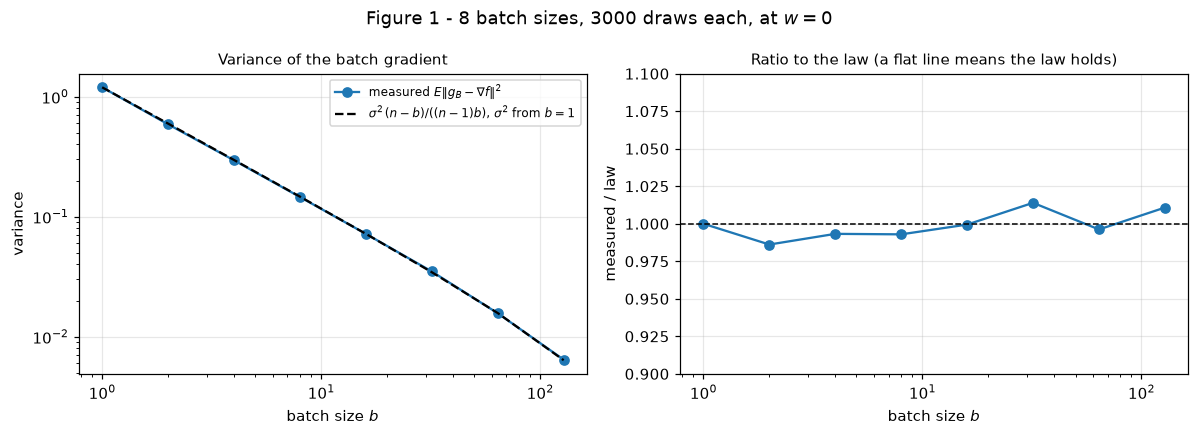

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

inner = sizes[:-1]
ax[0].loglog(inner, measured[:-1], "o-", label=r"measured $E\|g_B-\nabla f\|^2$")
sigma2 = measured[0] / ((n - 1) / (n - 1))            # the b=1 value pins the constant
law = [sigma2 * (n - bs) / ((n - 1) * bs) for bs in inner]
ax[0].loglog(inner, law, "k--", label=r"$\sigma^2\,(n-b)/((n-1)b)$, $\sigma^2$ from $b=1$")
ax[0].set_xlabel("batch size $b$")
ax[0].set_ylabel("variance")
ax[0].set_title("Variance of the batch gradient")
ax[0].legend(fontsize=8)

ax[1].semilogx(inner, [measured[i] / law[i] for i in range(len(inner))], "o-")
ax[1].axhline(1.0, color="k", ls="--", lw=1)
ax[1].set_xlabel("batch size $b$")
ax[1].set_ylabel("measured / law")
ax[1].set_ylim(0.9, 1.1)
ax[1].set_title("Ratio to the law (a flat line means the law holds)")

fig.suptitle(f"Figure 1 - {len(inner)} batch sizes, 3000 draws each, at $w=0$")
fig.tight_layout()
plt.show()

**Figure 1.** The left panel is a straight line of slope $-1$ over two decades: doubling
the batch halves the variance.

The right panel is the honest test. The law fixes the *shape* but not the constant
$\sigma^2$, so we read $\sigma^2$ off the $b = 1$ column and plot measured/predicted. The
leftmost point is therefore $1$ by construction and proves nothing; the claim is about
the other seven, which stay inside $\pm 1.5\%$ of it across two decades of $b$. A flat
line is the law holding. A line that drifted would mean the $1/b$ shape is wrong.

The `||bias||` column is small and shrinking like $1/\sqrt{3000}$ - that is Monte-Carlo
noise in our own measurement, not bias in the estimator. The last row settles it: at
$b = n$ there is one possible batch, the bias is $10^{-14}$ and the variance $10^{-32}$.
Both are zero up to floating point.

> **The trade you are making.** Halving the variance costs twice the work per step. But
> the variance enters the *error* under a square root, so four times the work buys you
> one bit. That is a terrible exchange rate, and it is why small batches win - see Sec. 2.

---

## Exercise 2 - SGD  *(~ 55 min)*

Implement `SGD.minimize`. Per epoch: reshuffle the indices, walk them in blocks of
`batch_size`, step on each block. The step at epoch `k` is `lr / (1 + lr_decay*k)`.

Use the **injected** `self.rng`, never `np.random.*` directly - that is what makes a run
reproducible from a seed.

Three conventions the tests rely on, because they are choices rather than consequences:

- **One `StepEvent` per epoch, not per batch**, measured on the *full* objective. An epoch
  is the only unit on which two batch sizes can be compared.
- **Keep the short last batch**, or you quietly drop up to `batch_size - 1` samples every
  epoch.
- **`converged` is `False`.** `SGD` spends its epoch budget; day 2 already decided that
  exhausting a budget is not convergence.

Then verify: `batch_size = n_samples` must reproduce gradient descent **exactly** at the
same fixed step, and the same seed must give identical runs.

**Open:** `src/optlab/optimizers/stochastic.py`

In [30]:
check("-m", "day3")

...........................................                              [100%]
43 passed, 194 deselected in 0.21s

PASSED


<details>
<summary><b>Plan B</b> - open only if you are stuck for more than ten minutes</summary>

For `L*`, run your day-2 gradient descent to a very tight tolerance first, and cache the value.

</details>

## 2. Count epochs, not iterations

Comparing $b = 1$ and $b = 128$ by iteration count is meaningless - the $b=1$ step is
128 times cheaper. The fair unit is the **epoch**: one pass over the data, i.e. the same
number of per-sample gradient evaluations whatever $b$ is. That is why your `SGD` takes
`n_epochs` and not `max_iter`.

First a sanity check that ties this notebook to the last one. At $b = n$ every batch is
the whole dataset, so SGD *is* gradient descent with a fixed step. Not approximately -
exactly, to the last bit.

In [22]:
n_ep = 25
lr = 0.3

hist = History()
res = SGD(batch_size=n, lr=lr, n_epochs=n_ep,
          rng=np.random.default_rng(0), observers=[hist]).minimize(loss, w0)

w_manual = w0.copy()
for _ in range(n_ep):
    w_manual = w_manual - lr * loss.gradient(w_manual)

print("SGD with b = n :", res.x)
print("hand-written GD:", w_manual)
print(f"max |difference| = {np.max(np.abs(res.x - w_manual)):.3e}")

SGD with b = n : [ 0.539049  0.677107  0.611337  0.387461 -0.141083]
hand-written GD: [ 0.539049  0.677107  0.611337  0.387461 -0.141083]
max |difference| = 2.220e-16


If that difference is not at the $10^{-16}$ level, your `SGD` is doing something extra -
a different step-size convention, a stray decay, a partial last batch handled wrongly.
Fix it here, before the noise makes it invisible.

Now the same budget of 40 epochs, spent at five different batch sizes.

In [23]:
batch_sizes = [1, 8, 32, 128, n]
runs = {}

print(f"{'b':>5} {'steps/epoch':>12} {'steps total':>12} {'final gap':>13}")
for bs in batch_sizes:
    h = History()
    SGD(batch_size=bs, lr=0.3, n_epochs=40,
        rng=np.random.default_rng(3), observers=[h]).minimize(loss, w0)
    runs[bs] = h
    per_epoch = int(np.ceil(n / bs))
    print(f"{bs:5d} {per_epoch:12d} {per_epoch * 40:12d} {h.values[-1] - f_star:13.4e}")

    b  steps/epoch  steps total     final gap
    1          400        16000    5.0908e-02
    8           50         2000    4.0840e-04
   32           13          520    2.4181e-04
  128            4          160    7.8210e-04
  400            1           40    1.0833e-02


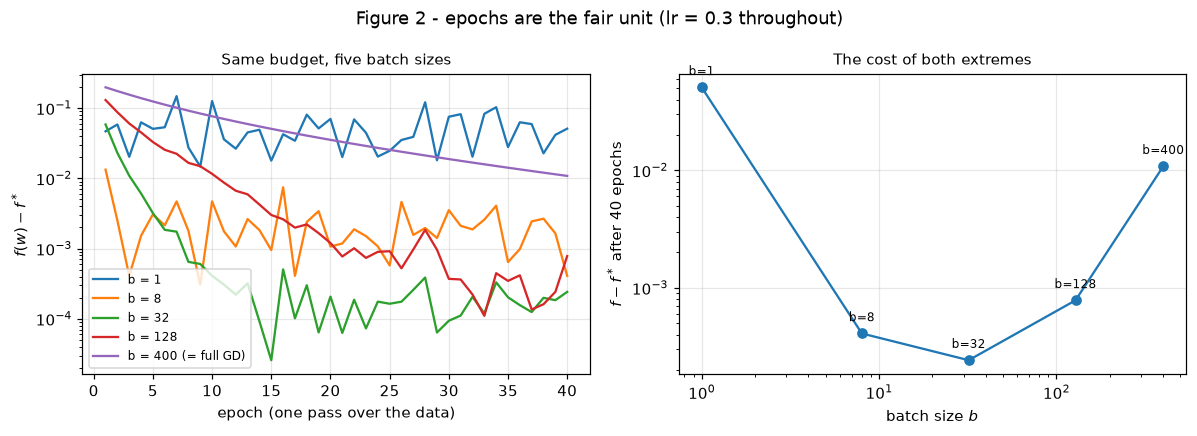

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

for bs in batch_sizes:
    gaps = np.maximum(np.array(runs[bs].values) - f_star, 1e-16)
    ax[0].semilogy(np.arange(1, len(gaps) + 1), gaps,
                   label=f"b = {bs}" + (" (= full GD)" if bs == n else ""))
ax[0].set_xlabel("epoch (one pass over the data)")
ax[0].set_ylabel(r"$f(w) - f^*$")
ax[0].set_title("Same budget, five batch sizes")
ax[0].legend(fontsize=8)

finals = [runs[bs].values[-1] - f_star for bs in batch_sizes]
ax[1].loglog(batch_sizes, finals, "o-")
for bs, fv in zip(batch_sizes, finals):
    ax[1].annotate(f"b={bs}", (bs, fv), textcoords="offset points",
                   xytext=(0, 8), ha="center", fontsize=8)
ax[1].set_xlabel("batch size $b$")
ax[1].set_ylabel(r"$f - f^*$ after 40 epochs")
ax[1].set_title("The cost of both extremes")

fig.suptitle("Figure 2 - epochs are the fair unit (lr = 0.3 throughout)")
fig.tight_layout()
plt.show()

**The right panel is a U, and both walls are instructive.**

At $b = n$ the steps are exact but there are only forty of them. At $b = 1$ there are
16 000 steps and the result is *worse*, because each gradient comes from a single sample
and the iterate rattles around the minimum instead of sitting in it. The best $b$ here is
32, some 45 times better than $b = n$ **for identical cost** - that is the whole practical
content of mini-batching.

The left panel says why. $b = 1$ flattens within a few epochs and then rattles; $b = 128$
and $b = n$ are still descending at epoch 40. So the two walls have different causes: the
right one is *too few steps*, the left one is a floor that more steps cannot get below.

## 3. The noise floor, and why your `SGD` beats the textbook

Gradient descent with a fixed step converges: Labwork 2 showed the error shrinking by a
constant factor forever. Stochastic gradient descent with a fixed step **does not**. It
falls quickly, then stops at a level set by the step size - the *noise floor*.

The reason is a balance. The descent term pulls the error down in proportion to $\alpha$;
the noise injected by the sampling pushes it up in proportion to $\alpha^2 \sigma^2$.
They meet at a nonzero error. The standard textbook statement is

$$\lim_{k\to\infty}\ \mathbb{E}\,[\,f(w_k) - f^*\,] \;=\; O(\alpha) .$$

Let us test that. Four step sizes, long enough to plateau, and we average the gap over
the last quarter of the run so that we are measuring the floor and not one lucky iterate.

In [26]:
def floor_of(lr, mode, b=8, sweeps=800, seed=7):
    """Average gap over the last quarter of a long constant-step run.

    mode="reshuffle" is what your SGD does: one permutation per epoch, so every
    sample is used exactly once. mode="iid" draws each batch independently, which
    is the assumption the O(alpha) analysis is built on.
    """
    gen = np.random.default_rng(seed)
    w = w0.copy()
    trace = []
    for _ in range(sweeps):
        if mode == "reshuffle":
            order = gen.permutation(n)
            batches = [order[i:i + b] for i in range(0, n, b)]
        else:
            batches = [gen.integers(0, n, size=b) for _ in range(n // b)]
        for idx in batches:
            w = w - lr * loss.batch_gradient(w, idx)
        trace.append(loss.value(w) - f_star)
    trace = np.array(trace)
    return float(trace[3 * len(trace) // 4:].mean()), trace


lrs = [0.4, 0.2, 0.1, 0.05]
floors, traces = {}, {}
for mode in ("reshuffle", "iid"):
    for lr in lrs:
        floors[mode, lr], traces[mode, lr] = floor_of(lr, mode)

print(f"{'lr':>6} {'reshuffle':>13} {'iid':>13}")
for lr in lrs:
    print(f"{lr:6.2f} {floors['reshuffle', lr]:13.4e} {floors['iid', lr]:13.4e}")

slopes = {m: np.polyfit(np.log(lrs), np.log([floors[m, lr] for lr in lrs]), 1)[0]
          for m in ("reshuffle", "iid")}
print(f"\nlog-log slope   reshuffle {slopes['reshuffle']:.2f}   iid {slopes['iid']:.2f}")
print("(the textbook O(alpha) prediction is a slope of 1)")

    lr     reshuffle           iid
  0.40    3.9427e-03    8.3219e-03
  0.20    7.8103e-04    4.0250e-03
  0.10    1.1316e-04    1.9569e-03
  0.05    1.4376e-05    9.4443e-04

log-log slope   reshuffle 2.71   iid 1.05
(the textbook O(alpha) prediction is a slope of 1)


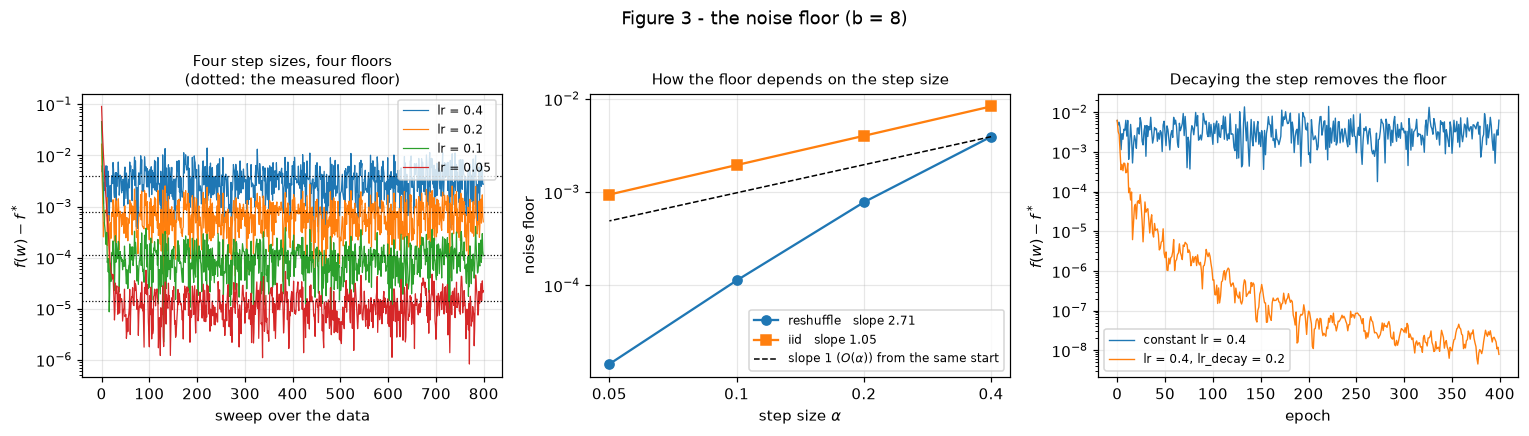

after 400 epochs:  constant 6.3089e-03   decaying 7.9077e-09
the decaying run's last step was 0.00495, down from 0.4 -- a factor of 81


In [27]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))

for lr in lrs:
    ax[0].semilogy(traces["reshuffle", lr], lw=0.8, label=f"lr = {lr}")
    ax[0].axhline(floors["reshuffle", lr], color="k", ls=":", lw=0.8)
ax[0].set_xlabel("sweep over the data")
ax[0].set_ylabel(r"$f(w) - f^*$")
ax[0].set_title("Four step sizes, four floors\n(dotted: the measured floor)")
ax[0].legend(fontsize=8)

for mode, marker in (("reshuffle", "o-"), ("iid", "s-")):
    vals = [floors[mode, lr] for lr in lrs]
    ax[1].loglog(lrs, vals, marker, label=f"{mode}   slope {slopes[mode]:.2f}")
# Anchor the reference at the reshuffling run's largest step, so the gap between the
# blue curve and the dashed line *is* the improvement over the textbook rate.
ref = np.array(lrs) * floors["reshuffle", lrs[0]] / lrs[0]
ax[1].loglog(lrs, ref, "k--", lw=1,
             label=r"slope 1 ($O(\alpha)$) from the same start")
ax[1].set_xlabel(r"step size $\alpha$")
ax[1].set_xticks(lrs)
ax[1].set_xticklabels([str(v) for v in lrs])
ax[1].minorticks_off()
ax[1].set_ylabel("noise floor")
ax[1].set_title("How the floor depends on the step size")
ax[1].legend(fontsize=8)

h_const, h_decay = History(), History()
SGD(batch_size=8, lr=0.4, n_epochs=400,
    rng=np.random.default_rng(7), observers=[h_const]).minimize(loss, w0)
SGD(batch_size=8, lr=0.4, n_epochs=400, lr_decay=0.2,
    rng=np.random.default_rng(7), observers=[h_decay]).minimize(loss, w0)
for h, lab in ((h_const, "constant lr = 0.4"), (h_decay, "lr = 0.4, lr_decay = 0.2")):
    ax[2].semilogy(np.maximum(np.array(h.values) - f_star, 1e-16), lw=0.9, label=lab)
ax[2].set_xlabel("epoch")
ax[2].set_ylabel(r"$f(w) - f^*$")
ax[2].set_title("Decaying the step removes the floor")
ax[2].legend(fontsize=8)

fig.suptitle("Figure 3 - the noise floor (b = 8)")
fig.tight_layout()
plt.show()

print(f"after 400 epochs:  constant {h_const.values[-1] - f_star:.4e}"
      f"   decaying {h_decay.values[-1] - f_star:.4e}")
print(f"the decaying run's last step was {0.4 / (1 + 0.2 * 399):.5f}, "
      f"down from {0.4} -- a factor of {1 + 0.2 * 399:.0f}")

**Left: four runs, four plateaus.** Nothing is converging. Running longer buys nothing -
only a smaller step does.

**Middle - the interesting one.** The i.i.d. curve has slope about 1, the textbook
$O(\alpha)$. The reshuffling curve is far steeper, so **your implementation has a better
floor than the theory predicts**. Why: over one reshuffled sweep every sample is used
exactly once, so the sampling errors of the batches must sum to zero. Under i.i.d.
sampling they do not.

Do **not** take the measured exponent as a law - it moves with the seed and the problem.
What is robust is the comparison: reshuffling beats i.i.d., and the textbook rate
describes the version nobody uses.

> The theory was not wrong; it answered a question about a different algorithm than the
> one in your file. When a measurement disagrees with a bound, suspect the hypotheses.

**Right: the other way to remove the floor** - shrink $\alpha$ as you go. Your `lr_decay`
gives $\alpha_k = \alpha_0/(1 + \gamma k)$, which satisfies the Robbins-Monro conditions
$\sum \alpha_k = \infty$ and $\sum \alpha_k^2 < \infty$. Nearly six orders of
magnitude, from one extra argument. The schedule is asymptotically right for any positive
$\gamma$; on a finite budget $\gamma$ decides where you actually stop.

---

## Exercise 3 - Adam  *(~ 45 min)*

Implement `Adam.minimize`: the two moment accumulators, the bias correction, and the
per-coordinate step.

Both moments start at zero, so both are biased toward zero for the first several steps -
divide by `1 - beta_1^t` and `1 - beta_2^t` to correct, where `t` counts **steps, not epochs**.

Two checks:

1. The first step is `~ lr - sign(g)`, whatever the magnitude of `g`. Verify across six
   orders of magnitude.
2. Take your logistic problem, multiply **one** feature column by 1000, and compare. SGD
   is trapped: any step large enough to move the small-scale coordinates is unstable on
   the large-scale one. Adam barely notices.

That second result is the lecture's claim that Adam auto-standardizes the per-coordinate
scale - the optimizer-side answer to day 1's conditioning problem.

`Adam` keeps the same epoch conventions as `SGD` - same reshuffling, same one event per
epoch, same `converged = False`. Only the update rule changes, which is the point: two
optimizers, one loop shape, no shared base class needed.

**Open:** `src/optlab/optimizers/stochastic.py`

In [28]:
check("-m", "day3")

...........................................                              [100%]
43 passed, 194 deselected in 0.21s

PASSED


## 4. Where Adam earns its place

Adam is usually sold as "SGD with adaptive learning rates", which explains nothing. Here
is the concrete case it fixes.

Build a linear regression whose two features live on wildly different scales - one of
order $1$, one of order $10^{-3}$. This is not exotic; it is what happens when one column
is a count and another is a probability, and nobody standardised. Labwork 1 showed
what that does to $\kappa$.

In [31]:
n2 = 1500
scale_rng = np.random.default_rng(4242)
X2 = np.column_stack([scale_rng.normal(size=n2),
                      scale_rng.normal(scale=1e-3, size=n2)])
w_true2 = np.array([2.0, -1500.0])            # the small feature needs a huge weight
y2 = X2 @ w_true2 + scale_rng.normal(scale=0.1, size=n2)

problem = GLMLoss(X2, y2, SquaredError())
w0_2 = np.zeros(2)

H = X2.T @ X2 / n2
eigs = np.linalg.eigvalsh(H)
w_star2 = np.linalg.solve(H, X2.T @ y2 / n2)
f_star2 = problem.value(w_star2)

print(f"eigenvalues of the Hessian : {eigs}")
print(f"condition number kappa     : {eigs[-1] / eigs[0]:.4e}")
print(f"optimum w*                 : {w_star2}")
print(f"f(w*)                      : {f_star2:.6e}")

eigenvalues of the Hessian : [0.000001 0.973358]
condition number kappa     : 9.5541e+05
optimum w*                 : [    1.994279 -1503.581183]
f(w*)                      : 4.944702e-03


In [32]:
settings = [("SGD", SGD, [0.5, 1.0, 1.8]), ("Adam", Adam, [0.5, 2.0, 10.0])]
adaptive = {}

print(f"{'optimizer':>10} {'lr':>6} {'gap after 60 epochs':>22} {'best gap seen':>16}")
for name, cls, lr_list in settings:
    for lr in lr_list:
        h = History()
        cls(batch_size=32, lr=lr, n_epochs=60,
            rng=np.random.default_rng(1), observers=[h]).minimize(problem, w0_2)
        adaptive[name, lr] = h
        gaps = np.array(h.values) - f_star2
        print(f"{name:>10} {lr:6.1f} {gaps[-1]:22.4e} {gaps.min():16.4e}")

 optimizer     lr    gap after 60 epochs    best gap seen
       SGD    0.5             1.1624e+00       1.1484e+00
       SGD    1.0             1.1977e+00       1.1462e+00
       SGD    1.8             1.6416e+00       1.1439e+00
      Adam    0.5             9.4620e-02       9.4620e-02
      Adam    2.0             4.2310e-04       6.1522e-06
      Adam   10.0             7.9046e-02       1.1763e-05


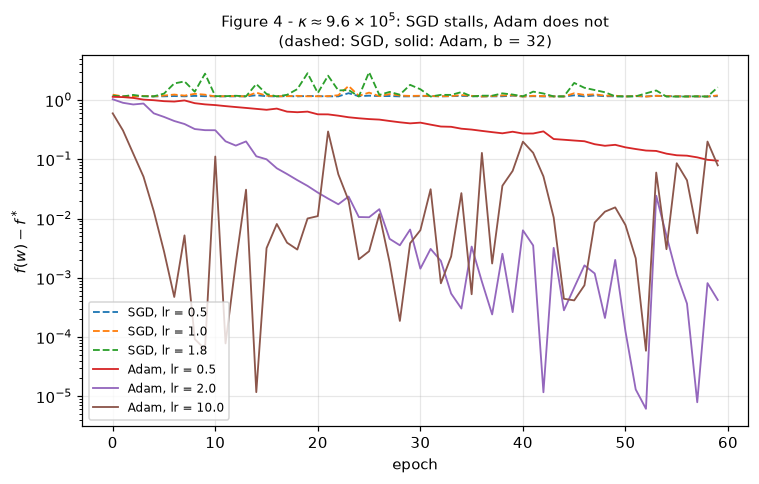

In [33]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for (name, lr), h in adaptive.items():
    style = "-" if name == "Adam" else "--"
    ax.semilogy(np.maximum(np.array(h.values) - f_star2, 1e-12), style,
                lw=1.2, label=f"{name}, lr = {lr}")
ax.set_xlabel("epoch")
ax.set_ylabel(r"$f(w) - f^*$")
ax.set_title(r"Figure 4 - $\kappa \approx 9.6\times 10^{5}$: SGD stalls, Adam does not"
             "\n(dashed: SGD, solid: Adam, b = 32)")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

**Three SGD runs spanning a factor of almost four in step size end up in the same place.**
They are not converging slowly, they have stopped. Raising the step does not help: the
largest usable step is set by the *stiff* direction (day 2: $\alpha < 2/L$), while all the
missing progress is in the *soft* one. No single number serves both.

Adam, same batches and same budget, is some 2700 times better at `lr = 2.0` - a value that
would make SGD explode instantly. **Adam's `lr` is not a step size in the same units**,
which is the most common source of confusion about it.

**Adam has a sweet spot too.** Read the `lr = 10.0` row: it found a better point than any
other run and then bounced away from it. Adam removes the *conditioning* problem, not the
noise floor. "Use Adam and stop tuning" is not a thing.

## 5. What Adam is actually doing

Adam keeps two running averages, of the gradient and of its square, and divides one by
the square root of the other:

$$m_t = \beta_1 m_{t-1} + (1-\beta_1) g_t, \qquad
v_t = \beta_2 v_{t-1} + (1-\beta_2) g_t^2,$$
$$w_{t+1} = w_t - \alpha \,\frac{\hat m_t}{\sqrt{\hat v_t} + \varepsilon},
\qquad \hat m_t = \frac{m_t}{1-\beta_1^t}, \quad \hat v_t = \frac{v_t}{1-\beta_2^t}.$$

The division is per-coordinate, and that is the whole trick. Look at the very first step,
where $m_1 = (1-\beta_1) g_1$ and $v_1 = (1-\beta_2) g_1^2$, so after bias correction
$\hat m_1 = g_1$ and $\sqrt{\hat v_1} = |g_1|$ and the ratio is $\operatorname{sign}(g_1)$
exactly. Let us check that against the arithmetic.

In [34]:
g1 = problem.gradient(w0_2)
beta1, beta2, eps = 0.9, 0.999, 1e-8

m1 = (1 - beta1) * g1
v1 = (1 - beta2) * g1 ** 2

print("gradient at w0          ", g1)
for lr_a in (2.0, 10.0):
    step_corrected = lr_a * (m1 / (1 - beta1)) / (np.sqrt(v1 / (1 - beta2)) + eps)
    print(f"  lr = {lr_a:<5} first step {step_corrected}"
          f"   lr*sign(g) {lr_a * np.sign(g1)}")

lr_a = 2.0
step_corrected = lr_a * (m1 / (1 - beta1)) / (np.sqrt(v1 / (1 - beta2)) + eps)
step_raw = lr_a * m1 / (np.sqrt(v1) + eps)
print()
print("at lr = 2.0, without bias correction ", step_raw)
print("ratio raw / corrected                ", step_raw / step_corrected)
print(f"predicted (1-b1)/sqrt(1-b2)           {(1 - beta1) / np.sqrt(1 - beta2):.6f}")

gradient at w0           [-1.878587  0.001452]
  lr = 2.0   first step [-2.        1.999986]   lr*sign(g) [-2.  2.]
  lr = 10.0  first step [-10.         9.999931]   lr*sign(g) [-10.  10.]

at lr = 2.0, without bias correction  [-6.324554  6.323178]
ratio raw / corrected                 [3.162277 3.161611]
predicted (1-b1)/sqrt(1-b2)           3.162278


The gradient components differ by three orders of magnitude - $-1.879$ and
$+1.452\times10^{-3}$ - and Adam's first step is $\pm\,$`lr` in **both**. It has thrown
the magnitude away and kept only the sign. That is why it crosses 1500 units of $w_2$
while SGD is still taking $\alpha \cdot 10^{-3}$-sized nudges there - and also why `lr`
is measured in units of $w$, not in units of $w$ per gradient.

The bias-correction check is worth reading twice. Without it the first step is $3.162$
times *larger*, matching $(1-\beta_1)/\sqrt{1-\beta_2}$ exactly. The usual story - "the
averages start at zero, so early steps are too small" - is only half true: $m$ and $v$
are both biased towards zero, the step is their ratio, and which bias wins depends on
$\beta_1$ against $\beta_2$. The correction is what makes the first step independent of
both.

Now watch the two coordinates move.

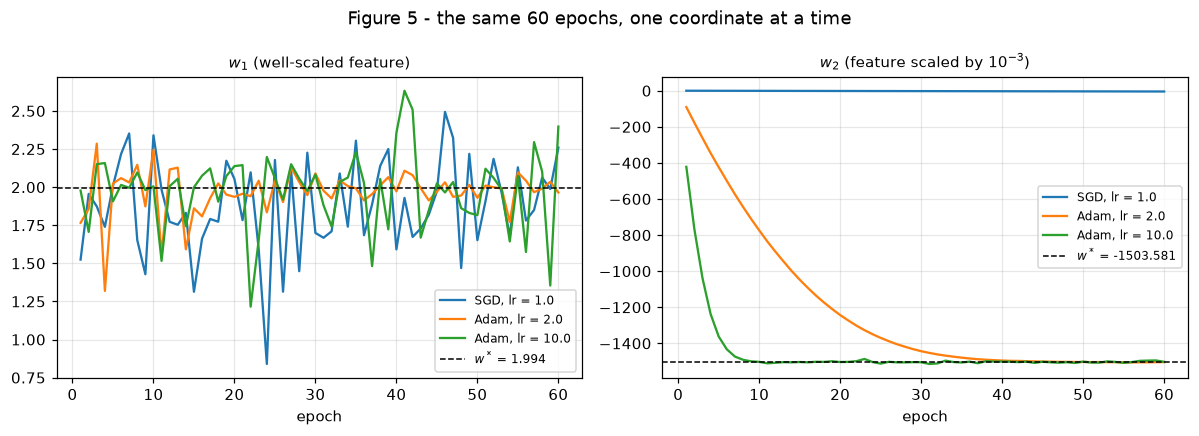

SGD   lr=1.0   w2 after 1 / 10 / 60 epochs:     -0.073     -0.721     -4.320   epochs to reach 1% of w*: never
Adam  lr=2.0   w2 after 1 / 10 / 60 epochs:    -90.812   -773.591  -1503.850   epochs to reach 1% of w*: 38
Adam  lr=10.0  w2 after 1 / 10 / 60 epochs:   -421.854  -1502.598  -1502.490   epochs to reach 1% of w*: 8

SGD   lr=1.0   w1 stays in [0.840, 2.494]   (width 1.654)
Adam  lr=2.0   w1 stays in [1.319, 2.285]   (width 0.966)
Adam  lr=10.0  w1 stays in [1.216, 2.633]   (width 1.417)


In [35]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharex=True)
pairs = [("SGD", 1.0), ("Adam", 2.0), ("Adam", 10.0)]

for coord, axis, target in ((0, ax[0], w_star2[0]), (1, ax[1], w_star2[1])):
    for name, lr in pairs:
        path = np.array([e.x[coord] for e in adaptive[name, lr].events])
        axis.plot(np.arange(1, len(path) + 1), path, label=f"{name}, lr = {lr}")
    axis.axhline(target, color="k", ls="--", lw=1, label=f"$w^*$ = {target:.3f}")
    axis.set_xlabel("epoch")
    axis.set_title(f"$w_{coord + 1}$ (well-scaled feature)" if coord == 0
                   else f"$w_{coord + 1}$ (feature scaled by $10^{{-3}}$)")
    axis.legend(fontsize=8)

fig.suptitle("Figure 5 - the same 60 epochs, one coordinate at a time")
fig.tight_layout()
plt.show()

for name, lr in pairs:
    w1_path = np.array([e.x[0] for e in adaptive[name, lr].events])
    path = np.array([e.x[1] for e in adaptive[name, lr].events])
    hit = np.where(np.abs(path - w_star2[1]) < 0.01 * abs(w_star2[1]))[0]
    print(f"{name:5s} lr={lr:<5} w2 after 1 / 10 / 60 epochs: "
          f"{path[0]:10.3f} {path[9]:10.3f} {path[-1]:10.3f}"
          f"   epochs to reach 1% of w*: {hit[0] + 1 if len(hit) else 'never'}")
print()
for name, lr in pairs:
    w1_path = np.array([e.x[0] for e in adaptive[name, lr].events])
    print(f"{name:5s} lr={lr:<5} w1 stays in [{w1_path.min():.3f}, {w1_path.max():.3f}]"
          f"   (width {w1_path.max() - w1_path.min():.3f})")

**All three methods hold $w_1$ near its optimum**, and the printed widths say SGD rattles
over a wider band than either Adam run - so the left panel is not evidence that Adam pays
for its speed with a worse $w_1$.

**The right panel is the whole story.** SGD's $w_2$ has covered a fraction of a percent of
its distance and is slowing down; it reaches 1% of the target *never*. Adam at `lr = 10.0`
is inside 1% by epoch 8, at `lr = 2.0` by epoch 38. Five times the step, about a fifth of
the epochs - `lr` sets the crossing speed, exactly as the sign-step picture says.

Tie this back to day 1. There, the cure for a huge $\kappa$ was to standardise the
columns. That remains the right fix: cheaper, one line, and it leaves a problem plain SGD
solves. Adam is what you reach for when you *cannot* fix the conditioning - scales that
differ per layer, or drift during training, or that you simply do not know.

---

## Exercise 4 - Batch size against noise  *(~ 25 min)*

Plot the loss against **epoch** (not iteration - equal data cost) for
`b in {1, 32, 256, n}`, and SGD against Adam.

Record wall-clock as well as epochs. Small batches take more steps per epoch and make more
progress per epoch, but each step has fixed overhead, so the wall-clock winner is usually
neither extreme. Keep the numbers: they feed the day-6 benchmark.

**Open:** no file - work in the notebook

In [36]:
print("Plot here: loss vs epoch for several batch sizes, then SGD vs Adam.")
print("Keep the numbers -- Labwork 6 reuses them.")

Plot here: loss vs epoch for several batch sizes, then SGD vs Adam.
Keep the numbers -- Labwork 6 reuses them.


---

## Checkpoint

Everything from day 1 to day 3 should be green before you leave, and
`mypy --strict` must be clean. A red type check counts as a failure.

In [37]:
check("-m", "day1 or day2 or day3")

........................................................................ [ 71%]
.............................                                            [100%]
101 passed, 136 deselected in 0.25s

PASSED


In [38]:
r = subprocess.run([sys.executable, "-m", "mypy"], cwd=OPTLAB,
                   capture_output=True, text=True)
print(r.stdout.strip() or r.stderr.strip())

src/optlab/optimizers/descent.py:41: error: "self" parameter missing for a non-static method (or an invalid type for self)  [misc]
src/optlab/optimizers/stochastic.py:71: error: "IBatchObjective" has no attribute "value"  [attr-defined]
src/optlab/optimizers/stochastic.py:72: error: "IBatchObjective" has no attribute "gradient"  [attr-defined]
src/optlab/optimizers/stochastic.py:85: error: "IBatchObjective" has no attribute "value"  [attr-defined]
src/optlab/optimizers/stochastic.py:86: error: "IBatchObjective" has no attribute "gradient"  [attr-defined]
src/optlab/optimizers/stochastic.py:151: error: "IBatchObjective" has no attribute "value"  [attr-defined]
src/optlab/optimizers/stochastic.py:152: error: "IBatchObjective" has no attribute "gradient"  [attr-defined]
src/optlab/optimizers/stochastic.py:165: error: "IBatchObjective" has no attribute "value"  [attr-defined]
src/optlab/optimizers/stochastic.py:166: error: "IBatchObjective" has no attribute "gradient"  [attr-defined]
src/o

---

## Before you leave

Answer these from cells you ran, not from memory.

1. A colleague reports that going from $b = 32$ to $b = 256$ "made each epoch converge
   worse". Is that a bug? Which panel settles it?
2. A run has plateaued at $f - f^* \approx 10^{-3}$ for 200 epochs. You have `lr` and
   `lr_decay`. Which one, and what do you expect to see?
3. The textbook says the noise floor is $O(\alpha)$ and your measurement disagrees.
   Without rerunning anything, which *one* line of `floor_of` explains it?
4. Someone sets Adam's `lr = 0.3` because "that worked for SGD". What is Adam's first step
   in units of $w$?

**Before day 4.** `Quadratic.hessian` and `GLMLoss.hessian` are needed from the first
figure of Labwork 4 on. `GLMLoss.hessian` is $X^\top D X / n$ with $D$ diagonal, and the
entries of $D$ come from `IPointwiseLoss.second_derivative` - you wrote that on day 1 and
have not used it since.

---

## Before the debrief

Be able to answer:

1. Why is the mini-batch gradient unbiased - and where does the argument use uniform
   sampling?
2. Why does a constant step not reach the exact optimum, when gradient descent with a
   constant step does?
3. What does Adam adapt *to*? Name the day-1 concept it compensates for.